# Tier 5: exotic options and stochastic volatility, hands on

Two new ideas in this tier.

1. **Exotic options** pay on the whole path of the stock, the way there as well as the end. An
   **Asian** pays on the average price, a **barrier** option dies if the stock touches a level,
   a **lookback** pays on the best price seen.
2. **Stochastic volatility.** Black-Scholes assumes one constant volatility. In the **Heston**
   model the variance (volatility squared) has its own random walk, which produces the
   volatility smile real option prices show.

```
src/ope/exotics.py    paths and the Asian: Monte Carlo and closed form
src/ope/barrier.py    barrier and lookback: Monte Carlo and closed forms
src/ope/heston.py     Heston: characteristic function, semi-analytical price, smile
src/ope/heston_mc.py  Heston by Monte Carlo
src/ope/plots/        plot_barrier_monitoring, plot_heston_smile
tests/                test_exotics.py, test_barrier.py, test_heston.py, test_heston_mc.py
```

Every Monte Carlo number comes with its standard error, and every closed form is compared with
a simulation that prices the same contract.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import quad

import ope
from ope.plots import plot_barrier_monitoring, plot_heston_smile

BASE = (100.0, 100.0, 1.0, 0.05, 0.20)  # S, K, T, r, sigma: 1 year, at the money
S, K, T, r, sigma = BASE
# feller violated (2 kappa theta = 0.12 < xi^2 = 0.36) -> the variance often hits 0
HP = ope.HestonParams(v0=0.04, kappa=1.5, theta=0.04, xi=0.6, rho=-0.7)

vanilla = ope.price("call", *BASE)
print(f"vanilla call, the reference for this notebook: {vanilla:.4f}")

vanilla call, the reference for this notebook: 10.4506


## 1. Paths instead of end points

In Tier 2 one normal draw gave the stock at expiry S_T, because a European payoff only needs
S_T. An exotic needs the price on several dates. The contract lists them: the **monitoring
dates**, here equally spaced at T/n, 2T/n, ..., T.

`gbm_paths` walks from date to date with the same exact log step as Tier 2:

log S(t + Δt) = log S(t) + (r − q − σ²/2)·Δt + σ·√Δt·z

Each step is exact, so the path is right at every date whatever n is. **The number of dates is
a term of the contract here.** A barrier checked every day and one checked
every month are two different options, with two different prices. Heston, later, is different:
there the step count is a numerical choice, with an error that shrinks as steps grow.

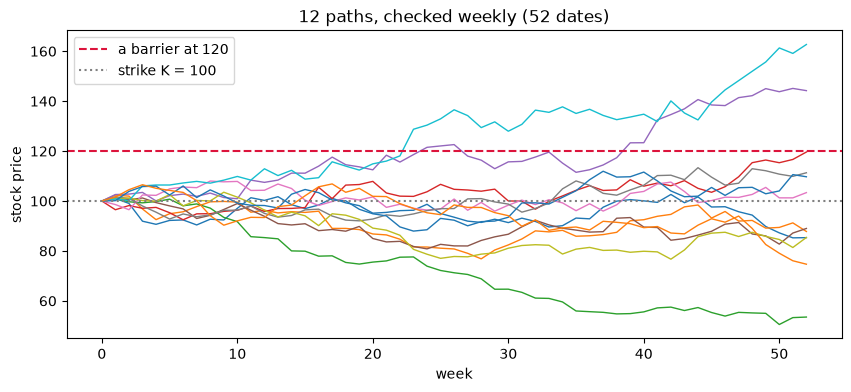

path 0: average 95.35, min 85.25, max 102.63, end 85.32


In [2]:
paths = ope.gbm_paths(S, T, r, sigma, n_dates=52, n_paths=12, rng=1)
weeks = np.arange(53)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(weeks, paths.T, lw=1)
ax.axhline(120, color="crimson", ls="--", label="a barrier at 120")
ax.axhline(K, color="gray", ls=":", label="strike K = 100")
ax.set_xlabel("week")
ax.set_ylabel("stock price")
ax.set_title("12 paths, checked weekly (52 dates)")
ax.legend()
plt.show()

p0 = paths[0]
print(
    f"path 0: average {p0[1:].mean():.2f}, min {p0.min():.2f}, max {p0.max():.2f}, end {p0[-1]:.2f}"
)

## 2. Asian options and the geometric control variate

An **Asian call** pays max(A − K, 0), where A is the average price over the dates. Averaging
removes much of the randomness, so it's cheaper than the vanilla, and harder to manipulate on
the last day. With the usual **arithmetic** average there is no closed form: a sum of lognormal
prices isn't lognormal.

The **geometric** average G = (S₁·S₂·…·Sₙ)^(1/n) has one. log G is the average of the log
prices, an average of normals, so it's normal:

- mean: log S + (r − q − σ²/2)·T·(n + 1)/(2n)
- variance: σ²·T·(n + 1)(2n + 1)/(6n²)

Black-Scholes on that normal gives the price (`asian_geometric_price`). Two checks below: the
simulation agrees with the formula, and on every path the geometric average sits just under the
arithmetic one (the average of the logs is below the log of the average).

geometric Asian, 12 dates: closed form 5.9402
inside the 95% interval for 94 of 100 seeds
correlation of the 2 payoffs across paths: 0.9996
arithmetic payoff >= geometric payoff on 100.0% of paths


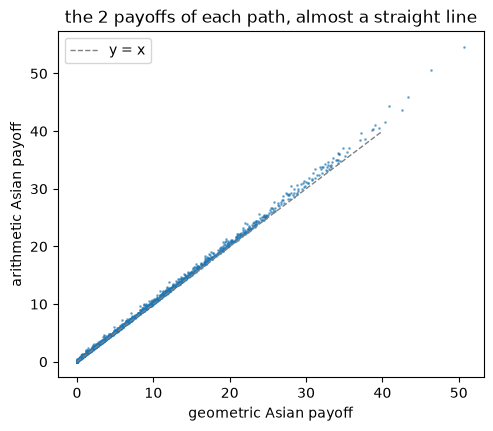

In [3]:
exact_geo = ope.asian_geometric_price("call", *BASE, n_dates=12)
inside = 0
for seed in range(100):
    lo, hi = ope.asian_mc(
        "call", *BASE, n_dates=12, n_paths=4_000, average="geometric", rng=seed
    ).ci95
    inside += lo <= exact_geo <= hi
print(f"geometric Asian, 12 dates: closed form {exact_geo:.4f}")
print(f"inside the 95% interval for {inside} of 100 seeds")

p = ope.gbm_paths(S, T, r, sigma, n_dates=12, n_paths=20_000, rng=2)[:, 1:]
disc = math.exp(-r * T)
pay_arith = disc * np.maximum(p.mean(axis=1) - K, 0)
pay_geo = disc * np.maximum(np.exp(np.log(p).mean(axis=1)) - K, 0)
print(f"correlation of the 2 payoffs across paths: {np.corrcoef(pay_arith, pay_geo)[0, 1]:.4f}")
print(f"arithmetic payoff >= geometric payoff on {np.mean(pay_arith >= pay_geo):.1%} of paths")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot(pay_geo[:3000], pay_arith[:3000], ".", ms=2, alpha=0.5)
ax.plot([0, 40], [0, 40], color="gray", ls="--", lw=1, label="y = x")
ax.set_xlabel("geometric Asian payoff")
ax.set_ylabel("arithmetic Asian payoff")
ax.set_title("the 2 payoffs of each path, almost a straight line")
ax.legend()
plt.show()

The method rests on that straight line. The geometric price has a closed form, so on a sample
of paths its error is visible: if the simulated geometric average came out 0.05 too high, the
arithmetic one almost surely did too. The **control variate** removes β times that error, with
β the slope of the line above (Tier 2 did the same with the stock price).

The stock was a decent control for a vanilla call (correlation 0.92 to 0.96 on the Tier 2
examples). The geometric Asian is a near perfect one for the arithmetic Asian (0.9996), and the
variance left over shrinks like 1 minus the correlation squared, so the gain is far larger.

In [4]:
print("dates  plain (std error)   control variate (std error)   gain   same error w/o it")
for n in (12, 52, 252):
    plain = ope.asian_mc("call", *BASE, n_dates=n, n_paths=100_000, rng=n)
    cv = ope.asian_mc("call", *BASE, n_dates=n, n_paths=100_000, control_variate=True, rng=n)
    gain = plain.std_error / cv.std_error
    a = f"{plain.estimate:.4f} ({plain.std_error:.4f})"
    b = f"{cv.estimate:.5f} ({cv.std_error:.5f})"
    print(f"{n:5d}  {a}     {b}             {gain:4.0f}x   {gain**2:,.0f}x the paths")

dates  plain (std error)   control variate (std error)   gain   same error w/o it


   12  6.1260 (0.0269)     6.15711 (0.00076)               35x   1,254x the paths


   52  5.8738 (0.0257)     5.85501 (0.00070)               37x   1,334x the paths


  252  5.7625 (0.0252)     5.78143 (0.00070)               36x   1,315x the paths


A standard error 36 times smaller at the same cost: without the control variate you'd need
about 36² ≈ 1,300 times more paths to get there. More averaging dates make the Asian cheaper
(the average of more prices moves less) and leave the gain unchanged.

## 3. Barrier options: discrete vs continuous monitoring

An **up-and-out call** is a call that dies (pays 0) the first time the stock reaches the barrier
H above spot. A **down-and-out** dies at H below spot. A knock-out is always cheaper than the
vanilla: same payoff, minus the paths that died.

There is a closed form (`barrier_price`, as in hull), but it assumes the barrier is watched
**continuously**, every instant. Real contracts check it on dates, often once a day at the close.
Between two checks the stock can cross H and come back without anyone looking. Fewer checks
means fewer knock-outs, so **the discretely checked option is worth more**.

The picture below shows it on one path: weekly checks see the cross, monthly checks miss it.

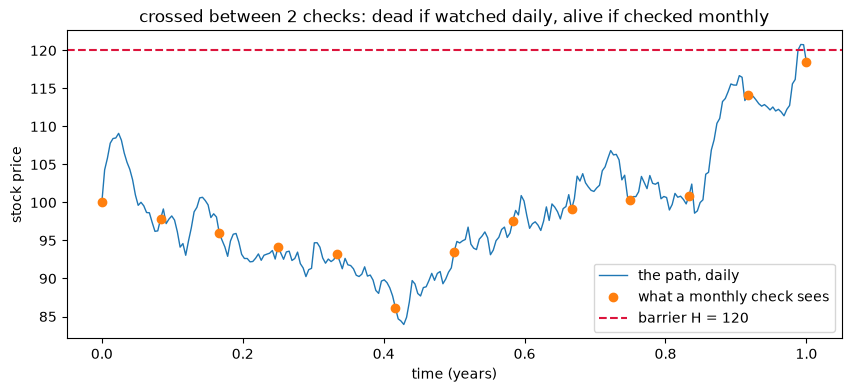

20 of 400 paths cross 120 between month ends without being seen at a month end


In [5]:
# find a path that crosses 120 between month ends but is below it at every month end
fine = ope.gbm_paths(S, T, r, sigma, n_dates=252, n_paths=400, rng=3)
monthly = fine[:, ::21]
missed = np.where((fine.max(axis=1) >= 120) & (monthly.max(axis=1) < 120))[0]
path = fine[missed[0]]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(253) / 252, path, lw=1, label="the path, daily")
ax.plot(np.arange(13) / 12, path[::21], "o", color="tab:orange", label="what a monthly check sees")
ax.axhline(120, color="crimson", ls="--", label="barrier H = 120")
ax.set_xlabel("time (years)")
ax.set_ylabel("stock price")
ax.set_title("crossed between 2 checks: dead if watched daily, alive if checked monthly")
ax.legend()
plt.show()
print(f"{len(missed)} of 400 paths cross 120 between month ends without being seen at a month end")

Below, the up-and-out call (K = 100, H = 120) is simulated with the barrier
checked on n dates, next to the continuous closed form. Two tools close the gap:

- **The Brownian bridge.** Given the log price at two dates, the chance it touched log H in between
  is exp(−2·a·b / (σ²·Δt)), with a and b the distances of the two ends to log H. Multiplying each
  path by its survival chance gives the continuously watched price from any number of dates
  (`monitoring="continuous"`).
- **The BGK shift** (Broadie, Glasserman and Kou, 1997). A barrier checked every Δt behaves like a
  continuous barrier moved away from spot by a factor exp(0.5826·σ·√Δt). Plug the moved barrier
  into the continuous formula and you get the discrete price almost for free.

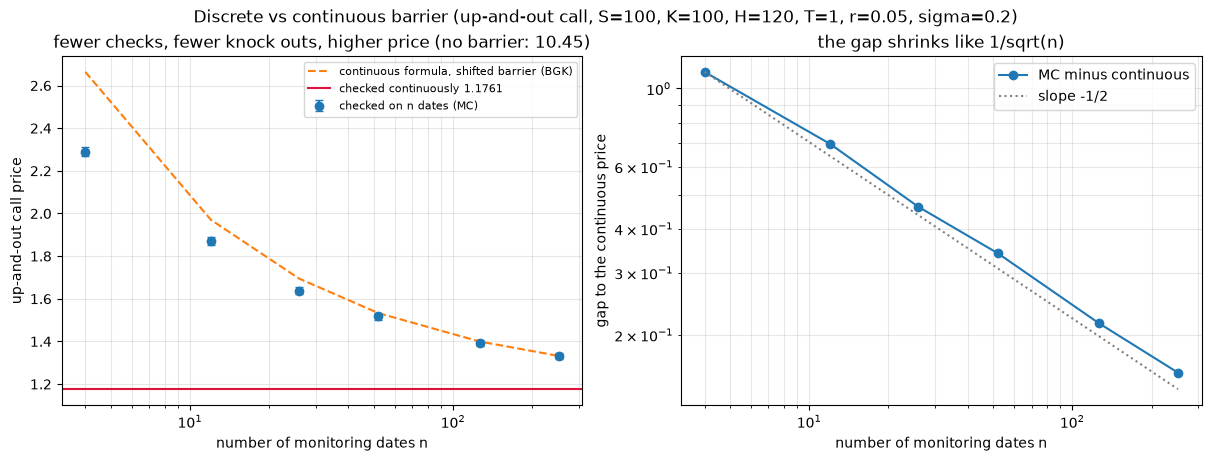

In [6]:
plot_barrier_monitoring("call", S, K, 120.0, T, r, sigma, kind="up-and-out")

In [7]:
for kind, H in (("up-and-out", 120.0), ("down-and-out", 90.0)):
    cont = ope.barrier_price("call", S, K, H, T, r, sigma, kind=kind)
    daily = ope.barrier_mc(
        "call", S, K, H, T, r, sigma, kind=kind, n_dates=252, n_paths=500_000, rng=10
    )
    bridge = ope.barrier_mc(
        "call",
        S,
        K,
        H,
        T,
        r,
        sigma,
        kind=kind,
        n_dates=252,
        n_paths=500_000,
        monitoring="continuous",
        rng=11,
    )
    bgk = ope.barrier_price("call", S, K, H, T, r, sigma, kind=kind, n_dates=252)
    print(f"{kind} call, H = {H:g}")
    print(f"  checked daily (MC)        {daily.estimate:.4f} +- {daily.std_error:.4f}")
    off = (bgk - daily.estimate) / daily.estimate
    print(f"  BGK shifted formula       {bgk:.4f}   ({off:+.1%} vs daily)")
    print(f"  watched continuously (MC) {bridge.estimate:.4f} +- {bridge.std_error:.4f}")
    print(f"  continuous closed form    {cont:.4f}")
    gap = daily.estimate - cont
    in_se = gap / daily.std_error
    print(
        f"  daily minus continuous:   {gap:+.4f} = {gap / cont:+.1%}, {in_se:.0f} standard errors\n"
    )

up-and-out call, H = 120
  checked daily (MC)        1.3267 +- 0.0048
  BGK shifted formula       1.3321   (+0.4% vs daily)
  watched continuously (MC) 1.1810 +- 0.0044
  continuous closed form    1.1761
  daily minus continuous:   +0.1506 = +12.8%, 31 standard errors



down-and-out call, H = 90
  checked daily (MC)        8.9144 +- 0.0208
  BGK shifted formula       8.9139   (-0.0% vs daily)
  watched continuously (MC) 8.6498 +- 0.0205
  continuous closed form    8.6655
  daily minus continuous:   +0.2490 = +2.9%, 12 standard errors



The last line of each block matters for testing: a daily-checked barrier tested on the
continuous formula would fail by 12 to 31 standard errors, and the code would be fine. Each
price must be compared with a reference for **the same contract**: daily with daily (the
BGK shift, and the exact case of a single check at expiry in the tests), continuous with
continuous (the bridge).

The gap is about 13% for the up-and-out but only about 3% for the down-and-out. The up-and-out call
dies where its payoff is largest, so every missed crossing is a big payoff kept.

## 4. Lookback options: the best price in hindsight

A **floating-strike lookback call** pays S_T − min S: you buy at the lowest price the stock
reached. The put pays max S − S_T: you sell at the highest. That hindsight is expensive, more
than the at-the-money vanilla. There is a closed form for continuous watching (Goldman, Sosin and
Gatto, 1979, `lookback_price`).

As with the barrier, a discrete check misses the true low between dates, so the discrete
lookback is worth **less** than the continuous one. With a single date (only today and expiry)
the payoff is S_T − min(S, S_T) = max(S_T − S, 0): the at-the-money vanilla call, an exact check.

In [8]:
cont = ope.lookback_price("call", S, T, r, sigma)
print(f"continuous closed form           {cont:.4f}")
for n in (1, 12, 52, 252):
    res = ope.lookback_mc("call", S, T, r, sigma, n_dates=n, n_paths=400_000, rng=20 + n)
    mc = f"{res.estimate:.4f} +- {res.std_error:.4f}"
    print(f"checked on {n:3d} dates (MC)       {mc}   gap {res.estimate - cont:+.4f}")
res = ope.lookback_mc(
    "call", S, T, r, sigma, n_dates=12, n_paths=400_000, monitoring="continuous", rng=30
)
mc = f"{res.estimate:.4f} +- {res.std_error:.4f}"
print(f"watched continuously, 12 dates   {mc}   (exact bridge minimum)")
print(f"at-the-money vanilla call        {vanilla:.4f}   (= the 1 date lookback)")

continuous closed form           17.2168
checked on   1 dates (MC)       10.4442 +- 0.0233   gap -6.7726
checked on  12 dates (MC)       14.6754 +- 0.0229   gap -2.5414


checked on  52 dates (MC)       15.9475 +- 0.0230   gap -1.2693


checked on 252 dates (MC)       16.6173 +- 0.0231   gap -0.5995


watched continuously, 12 dates   17.1995 +- 0.0230   (exact bridge minimum)
at-the-money vanilla call        10.4506   (= the 1 date lookback)


For continuous watching, the simulation draws the exact minimum of the Brownian bridge
between two dates, (a + b − √((b − a)² − 2σ²Δt·log u)) / 2 for a uniform u. It matches the
closed form with 12 dates.

## 5. The exotics next to the vanilla

All on the same stock (S = 100, σ = 20%, r = 5%, 1 year), calls struck at 100 where there is a
strike. Each is priced as a real contract would be, checked daily or monthly.

In [9]:
rows = [
    ("vanilla call", vanilla, "pays on S_T"),
    (
        "Asian, 12 monthly dates",
        ope.asian_mc(
            "call", *BASE, n_dates=12, n_paths=200_000, control_variate=True, rng=40
        ).estimate,
        "the average moves less than S_T",
    ),
    (
        "Asian, geometric (closed form)",
        ope.asian_geometric_price("call", *BASE, n_dates=12),
        "a lower average",
    ),
    (
        "down-and-out H = 90, daily",
        ope.barrier_mc(
            "call", *BASE[:2], 90.0, *BASE[2:], kind="down-and-out", n_paths=200_000, rng=41
        ).estimate,
        "loses the paths that dip",
    ),
    (
        "up-and-out H = 120, daily",
        ope.barrier_mc(
            "call", *BASE[:2], 120.0, *BASE[2:], kind="up-and-out", n_paths=200_000, rng=42
        ).estimate,
        "loses the paths that pay most",
    ),
    (
        "lookback call, daily",
        ope.lookback_mc("call", S, T, r, sigma, n_paths=200_000, rng=43).estimate,
        "buys at the low: hindsight costs",
    ),
]
for name, value, why in rows:
    print(f"{name:32s} {value:8.4f}   {value / vanilla:5.0%} of the vanilla   {why}")

vanilla call                      10.4506    100% of the vanilla   pays on S_T
Asian, 12 monthly dates            6.1555     59% of the vanilla   the average moves less than S_T
Asian, geometric (closed form)     5.9402     57% of the vanilla   a lower average
down-and-out H = 90, daily         8.9113     85% of the vanilla   loses the paths that dip
up-and-out H = 120, daily          1.3324     13% of the vanilla   loses the paths that pay most
lookback call, daily              16.6332    159% of the vanilla   buys at the low: hindsight costs


## 6. Heston: the variance gets its own random walk

Black-Scholes gives the stock one volatility for its whole life. Heston (1993) lets the
**variance** v (volatility squared) move:

- dS = (r − q)·S·dt + √v·S·dW₁
- dv = κ·(θ − v)·dt + ξ·√v·dW₂, with corr(dW₁, dW₂) = ρ

In plain words:
- **θ** (theta) is the long-run variance: 0.04 means 20% vol.
- **κ** (kappa) is how fast v is pulled back to θ: 1.5 closes about 78% of the gap in a year.
- **ξ** (xi), the **vol of vol**, is how noisy the variance is.
- **ρ** (rho) correlates the two noises. On equity indices it's negative: when the stock falls,
  volatility jumps.

The **Feller condition** 2κθ ≥ ξ² says the pull to θ is strong enough that the true variance never
touches 0. Here 2·1.5·0.04 = 0.12 < 0.36: violated, as calibrated parameters often are.

In [10]:
s, v = ope.heston_paths(S, T, r, HP, n_steps=252, n_paths=8, rng=5)
t = np.linspace(0, T, 253)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(t, s.T, lw=1)
a1.set_title("stock")
a1.set_xlabel("time (years)")
a2.plot(t, 100 * np.sqrt(np.maximum(v, 0)).T, lw=1)
a2.axhline(20, color="gray", ls="--", label="sqrt(theta) = 20%")
a2.set_title("volatility sqrt(v) in %, it moves")
a2.set_xlabel("time (years)")
a2.legend()
plt.show()
print(f"Feller condition holds: {HP.feller}")

Feller condition holds: False


**Full truncation.** The simulation steps forward with Euler: v_next = v + κ(θ − v)Δt + ξ√v·√Δt·z.
A large negative z can push v below 0, and √v then fails. The true variance stays at or above 0:
the negative values come from the time step. **Full truncation** (Lord, Koekkoek and van Dijk, 2010) lets the
stored v go negative but uses max(v, 0) in every term that needs it, so a negative v means
"no volatility for this step" and the drift pulls it back. With Feller violated, it's frequent:

In [11]:
for n in (4, 16, 64, 256):
    _, v = ope.heston_paths(S, T, r, HP, n_steps=n, n_paths=20_000, rng=n)
    print(f"{n:4d} steps a year: v < 0 after {np.mean(v[:, 1:] < 0):5.1%} of the steps")

   4 steps a year: v < 0 after 34.3% of the steps
  16 steps a year: v < 0 after 23.0% of the steps


  64 steps a year: v < 0 after 13.4% of the steps


 256 steps a year: v < 0 after  8.1% of the steps


## 7. The semi-analytical price, and the little Heston trap

Heston has no closed form like Black-Scholes, but the **characteristic function** of log S_T,
φ(u) = E[e^(iu·log S_T)], has one (`heston_cf`). Two
probabilities follow from it by one integral each (Gil-Pelaez inversion), and the price has the
Black-Scholes shape:

call = S·e^(−qT)·P₁ − K·e^(−rT)·P₂

P₂ is the risk-neutral probability of finishing in the money, Heston's version of N(d₂), and P₁
the same under the stock measure, Heston's N(d₁).

**The trap.** Heston's 1993 formula has a complex logarithm, log((1 − g·e^(dT)) / (1 − g)). As u
grows its argument circles the origin, and NumPy's `log` (like every library's) jumps by 2π when it
crosses the negative real axis. Albrecher et al. (2007), *The Little Heston Trap*, picked the other
square root −d: the same function on paper, its argument stays on one side, and e^(−dT) shrinks
where e^(dT) overflows. Below, both forms along u, at 1 year and at 5 years.

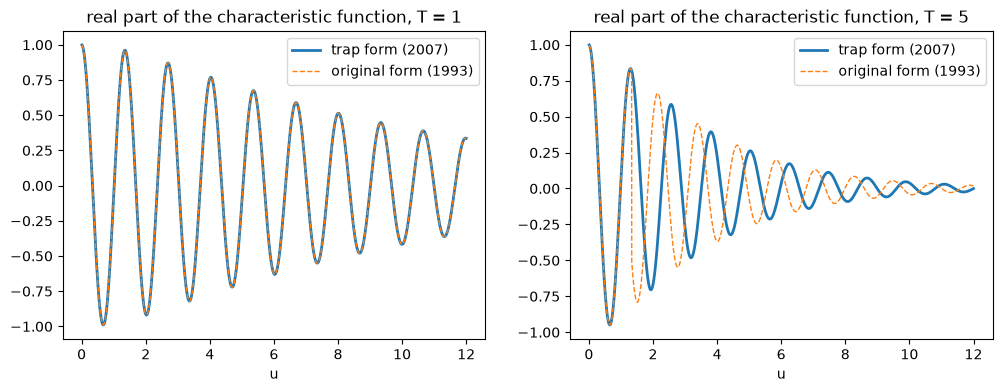

 T    heston_price   original form
   1       9.8713         9.8713
   2      15.5664        24.7573
   5      29.0895        16.3851
  10      45.6581        21.2868


In [12]:
u = np.linspace(0.01, 12, 3000)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, mat in zip(axes, (1.0, 5.0), strict=True):
    ax.plot(u, ope.heston_cf(u, S, mat, r, HP).real, lw=2, label="trap form (2007)")
    ax.plot(
        u,
        ope.heston_cf(u, S, mat, r, HP, form="original").real,
        lw=1,
        ls="--",
        label="original form (1993)",
    )
    ax.set_title(f"real part of the characteristic function, T = {mat:g}")
    ax.set_xlabel("u")
    ax.legend()
plt.show()


def call_from_cf(mat, form, upper):
    """the P1, P2 integrals cut at `upper`, done by hand to try the original form"""
    fwd, lk = S * math.exp(r * mat), math.log(K)

    def f(x, shift, scale):
        phi = ope.heston_cf(x + shift, S, mat, r, HP, form=form)[()]
        return float((np.exp(-1j * x * lk) * phi / (1j * x * scale)).real)

    p1 = 0.5 + quad(f, 0, upper, args=(-1j, fwd), limit=2000)[0] / math.pi
    p2 = 0.5 + quad(f, 0, upper, args=(0j, 1.0), limit=2000)[0] / math.pi
    return S * p1 - K * math.exp(-r * mat) * p2


# cut at u = 300 / T, where e^(dT) still fits in a float
print(" T    heston_price   original form")
for mat in (1.0, 2.0, 5.0, 10.0):
    good, bad = ope.heston_price("call", S, K, mat, r, HP), call_from_cf(mat, "original", 300 / mat)
    print(f"{mat:4g}   {good:10.4f}     {bad:10.4f}")

At 1 year the two forms are the same curve. At 5 years the original jumps near u = 1.34 and
the price comes out at 16.39 instead of 29.09, and nothing warns about it. Integrated all the way to infinity, the original form even returns `nan`, because
e^(dT) overflows. The library integrates the trap form to infinity, and in the tests it agrees
with a second, independent integral (Lewis, 2000) to 1e-7.

## 8. Monte Carlo vs the semi-analytical price: bias is not noise

The Monte Carlo price has two errors:
- **noise**, which the standard error measures and more paths shrink;
- **bias** from the Euler time step, which more paths do *not* shrink. Only more steps do.

Below, 1,000,000 paths per run, and the step count doubled each time. With few steps the price is
dozens of standard errors off: that's bias, and reading it as noise would be wrong.

In [13]:
exact = ope.heston_price("call", S, K, T, r, HP)
print(f"semi-analytical: {exact:.4f}\n")
steps = [2, 4, 8, 16, 32, 64, 128]
bias, err = [], []
print(" steps    MC price (std error)   MC minus exact   in std errors")
for n in steps:
    res = ope.heston_mc("call", S, K, T, r, HP, n_steps=n, n_paths=1_000_000, rng=100 + n)
    bias.append(res.estimate - exact)
    err.append(res.std_error)
    mc = f"{res.estimate:.4f} ({res.std_error:.4f})"
    print(f"{n:6d}    {mc}        {bias[-1]:+.4f}       {bias[-1] / res.std_error:+6.1f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(
    steps, bias, yerr=1.96 * np.array(err), fmt="o-", capsize=3, label="MC minus exact, 95% bars"
)
ax.axhline(0, color="gray", ls="--")
ax.set_xscale("log", base=2)
ax.set_xlabel("time steps per year")
ax.set_ylabel("error of the MC price")
ax.set_title("the bias shrinks with steps, the error bar with paths")
ax.legend()
plt.show()

semi-analytical: 9.8713

 steps    MC price (std error)   MC minus exact   in std errors


     2    11.0128 (0.0138)        +1.1415        +82.8


     4    10.5846 (0.0119)        +0.7133        +60.0


     8    10.1912 (0.0108)        +0.3199        +29.6


    16    9.9833 (0.0104)        +0.1120        +10.8


    32    9.9326 (0.0102)        +0.0613         +6.0


    64    9.9120 (0.0102)        +0.0407         +4.0


   128    9.8587 (0.0101)        -0.0126         -1.2


The bias roughly halves each time the steps double, the signature of a first-order scheme.
At 64 steps it's down to about 0.03, 0.3% of the price: still 4 standard errors with a million
paths, but a seventh of the noise of the 2,000-path runs the tests use. Pick the steps for the
error bar you need: halving the noise takes 4 times the paths, halving the bias twice the steps.
The tests check that the 64-step 95% interval holds the exact price about 95% of the time over 200
seeds, and separately that the 4-step bias is real (over 10 standard errors).

## 9. Vol of vol to zero: back to Black-Scholes

With ξ = 0 the variance stops being random: it slides from v0 to θ along
E[v_t] = θ + (v0 − θ)·e^(−κt). A deterministic but moving variance is Black-Scholes with the
average variance over the option's life, σ_eff² = θ + (v0 − θ)·(1 − e^(−κT)) / (κT).

As ξ shrinks, the Heston price must converge to Black-Scholes at σ_eff. Here v0 = 0.09 (30%
vol today) and θ = 0.04 (20% long run), so σ_eff = 25.7%.

Black-Scholes at sigma_eff = 0.2567: 12.589676

xi = 0.6     Heston 11.879031   gap -7.11e-01
xi = 0.3     Heston 12.439985   gap -1.50e-01
xi = 0.1     Heston 12.592874   gap +3.20e-03
xi = 0.03    Heston 12.596308   gap +6.63e-03
xi = 0.01    Heston 12.592432   gap +2.76e-03
xi = 0.001   Heston 12.589976   gap +3.00e-04
xi = 0.0001  Heston 12.589706   gap +3.03e-05


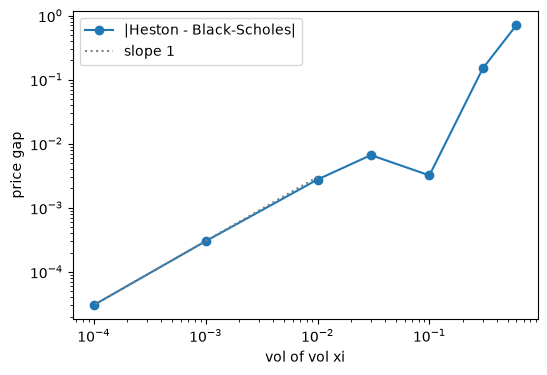

In [14]:
p0 = ope.HestonParams(v0=0.09, kappa=1.5, theta=0.04, xi=0.6, rho=-0.7)
seff = p0.effective_vol(T)
bs = ope.price("call", S, K, T, r, seff)
print(f"Black-Scholes at sigma_eff = {seff:.4f}: {bs:.6f}\n")
xis = [0.6, 0.3, 0.1, 0.03, 1e-2, 1e-3, 1e-4]
gaps = []
for xi in xis:
    h = ope.heston_price("call", S, K, T, r, ope.HestonParams(0.09, 1.5, 0.04, xi, -0.7))
    gaps.append(abs(h - bs))
    print(f"xi = {xi:<7g} Heston {h:.6f}   gap {h - bs:+.2e}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(xis, gaps, "o-", label="|Heston - Black-Scholes|")
ax.loglog(xis[-3:], gaps[-1] * np.array(xis[-3:]) / xis[-1], ":", color="gray", label="slope 1")
ax.set_xlabel("vol of vol xi")
ax.set_ylabel("price gap")
ax.legend()
plt.show()

Once ξ is small the gap falls in step with ξ: 10 times less vol of vol, 10 times less gap.
Two side notes. Around ξ = 0.1 the first- and second-order effects of ξ nearly cancel, so the
gap isn't monotone there. And below ξ ≈ 1e-5 the formula itself loses digits: it multiplies
κθ/ξ² (huge) by a bracket that is almost 0. That's why `HestonParams` asks for ξ > 0, and why
the test stops at 1e-4.

## 10. The smile

Take Heston prices across strikes and ask Black-Scholes, through the Tier 1 solver, which
volatility each one needs (`heston_implied_vol`). In a Black-Scholes world the answer would be
the same for every strike, a flat line. Heston gives a curve:

- **ρ < 0 tilts it into a skew.** When the stock falls, the vol rises, so big drops are more
  likely than in Black-Scholes: low-strike puts are dearer (higher implied vol), high-strike
  calls cheaper. That's the shape of the S&P 500 smile.
- **ρ = 0 gives a symmetric smile.** Random vol makes both tails fatter.
- **ξ sets how curved it is**, and κ how fast it flattens with maturity.

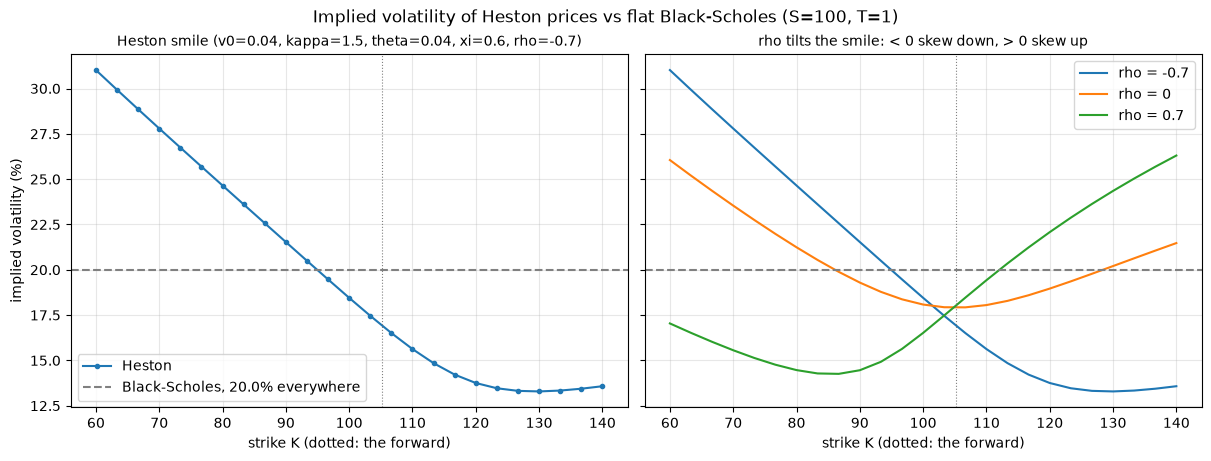

In [15]:
plot_heston_smile(S, T, r, HP)

In [16]:
strikes = np.array([70.0, 80.0, 90.0, 100.0, 110.0, 120.0, 130.0])
vols = ope.heston_implied_vol(S, strikes, T, r, HP)
print("strike      " + "  ".join(f"{k:6.0f}" for k in strikes))
print("implied vol " + "  ".join(f"{100 * v:5.1f}%" for v in vols))

strike          70      80      90     100     110     120     130
implied vol  27.8%   24.6%   21.5%   18.5%   15.6%   13.8%   13.3%


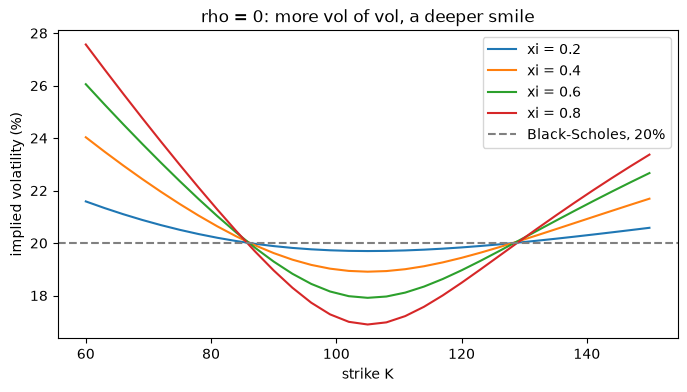

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
ks = np.linspace(60, 150, 31)
for xi in (0.2, 0.4, 0.6, 0.8):
    p = ope.HestonParams(0.04, 1.5, 0.04, xi, 0.0)
    ax.plot(ks, 100 * ope.heston_implied_vol(S, ks, T, r, p), label=f"xi = {xi:g}")
ax.axhline(20, color="gray", ls="--", label="Black-Scholes, 20%")
ax.set_xlabel("strike K")
ax.set_ylabel("implied volatility (%)")
ax.set_title("rho = 0: more vol of vol, a deeper smile")
ax.legend()
plt.show()

At the money, the Heston implied vol (18.5% with ρ = −0.7) sits below the 20% average vol. The
negative correlation moves probability into the left tail, and the money has to come from
somewhere: the center gets cheaper. Tier 6 does this in reverse: it starts from market
implied vols and searches for the Heston parameters that reproduce them.